# Problem Set 03 — Đọc dữ liệu trong một dự án AI
**Giảng viên: Nguyễn Bích Vân • IAI-UET-VNU • UET.MAT1052**

Tất cả dữ liệu trong bộ này là **giả lập mới phục vụ học tập**; không mô tả sản phẩm, sinh viên hoặc người dùng thật.

Mở cả thư mục bằng **File → Open Folder**, chọn **Select Kernel**, rồi chạy các ô từ trên xuống.
Kết quả nằm **ngay dưới ô mã**, không phải trong Terminal. Trong ô notebook, **Shift+Enter** chạy ô; dấu `PS ...>` và `>>` không thuộc mã Python.

Nếu thiếu thư viện, tạo ô Code và chạy `%pip install -r requirements.txt`, sau đó **Restart Kernel**. Không tự cài lại mỗi lần Run All.

## Chú ý
Bài 1–5 làm tay. Các ô dưới đây dành cho Bài 6–10. Mã nạp dữ liệu và các TODO không phải đáp án; cần viết cả mã lẫn nhận xét. Học cú pháp ở `00_Learn_Plotnine.ipynb` trước.

In [28]:
from pathlib import Path
import sys
print("Python cua kernel:", sys.executable)
import numpy as np
import pandas as pd
import plotnine
from IPython.display import display
from plotnine import (
    ggplot, aes, geom_histogram, after_stat, geom_col, geom_bar,
    geom_rect, geom_point, geom_boxplot, geom_line, geom_hline,
    facet_wrap, labs, scale_x_continuous, scale_y_continuous
)
print("NumPy:", np.__version__, "pandas:", pd.__version__,
      "plotnine:", plotnine.__version__)
# Chi sua neu khong mo VS Code dung thu muc da giai nen.
ROOT_OVERRIDE = ""  # Vi du: r"D:\PS03_AI_Student"
ROOT = Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else Path.cwd()
DATA = ROOT / "data"
if not DATA.is_dir():
    raise FileNotFoundError(f"Khong thay {DATA.resolve()}. Hay mo thu muc goi bai.")
print("Du lieu:", DATA.resolve())
OUT = ROOT / "bai_lam"
OUT.mkdir(exist_ok=True)

Python cua kernel: c:\Users\admin\AppData\Local\Programs\Python\Python313\python.exe
NumPy: 2.3.5 pandas: 2.2.3 plotnine: 0.15.3
Du lieu: C:\Users\admin\OneDrive\Documents\UET_2026_2027\MATH1052\MATH1052\PS03\data


## Bài 6 — Chatbot FAQ có thật sự phản hồi tập trung hơn?

Tệp `exercise06_responses.csv` ghi 960 lượt dùng trợ lý học tập, gồm tra cứu câu hỏi thường gặp (`FAQ`) và giải thích mã (`Code explanation`). Mỗi hàng là một lượt; `response_time_s` là thời gian từ lúc gửi đến khi nhận đủ phản hồi. Một số thời gian bị thiếu do bản ghi không đầy đủ; không thay ô trống bằng 0.

Câu hỏi: hai nhóm khác nhau về **phân phối thời gian phản hồi** như thế nào, chứ không chỉ nhóm nào được dùng nhiều hơn?

In [29]:
raw6 = pd.read_csv(DATA / "exercise06_responses.csv")
display(raw6.head())
print("Kich thuoc:", raw6.shape)
# Hay kiem tra cac cot, don vi va chinh sach du lieu thieu truoc khi lam bai.

,id,task,response_time_s
0,R0001,FAQ,1.78
1,R0002,FAQ,1.84
2,R0003,Code explanation,6.42
3,R0004,FAQ,NaN
4,R0005,FAQ,3.87


Kich thuoc: (960, 3)


### Câu 1
Vẽ hai histogram số đếm theo tác vụ, dùng chung các biên 0,1,2,...,20 giây. Giữ cùng thang trục ngang và trục dọc; có thể dùng `facet_wrap`.

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_bin : Removed 12 rows containing non-finite values.


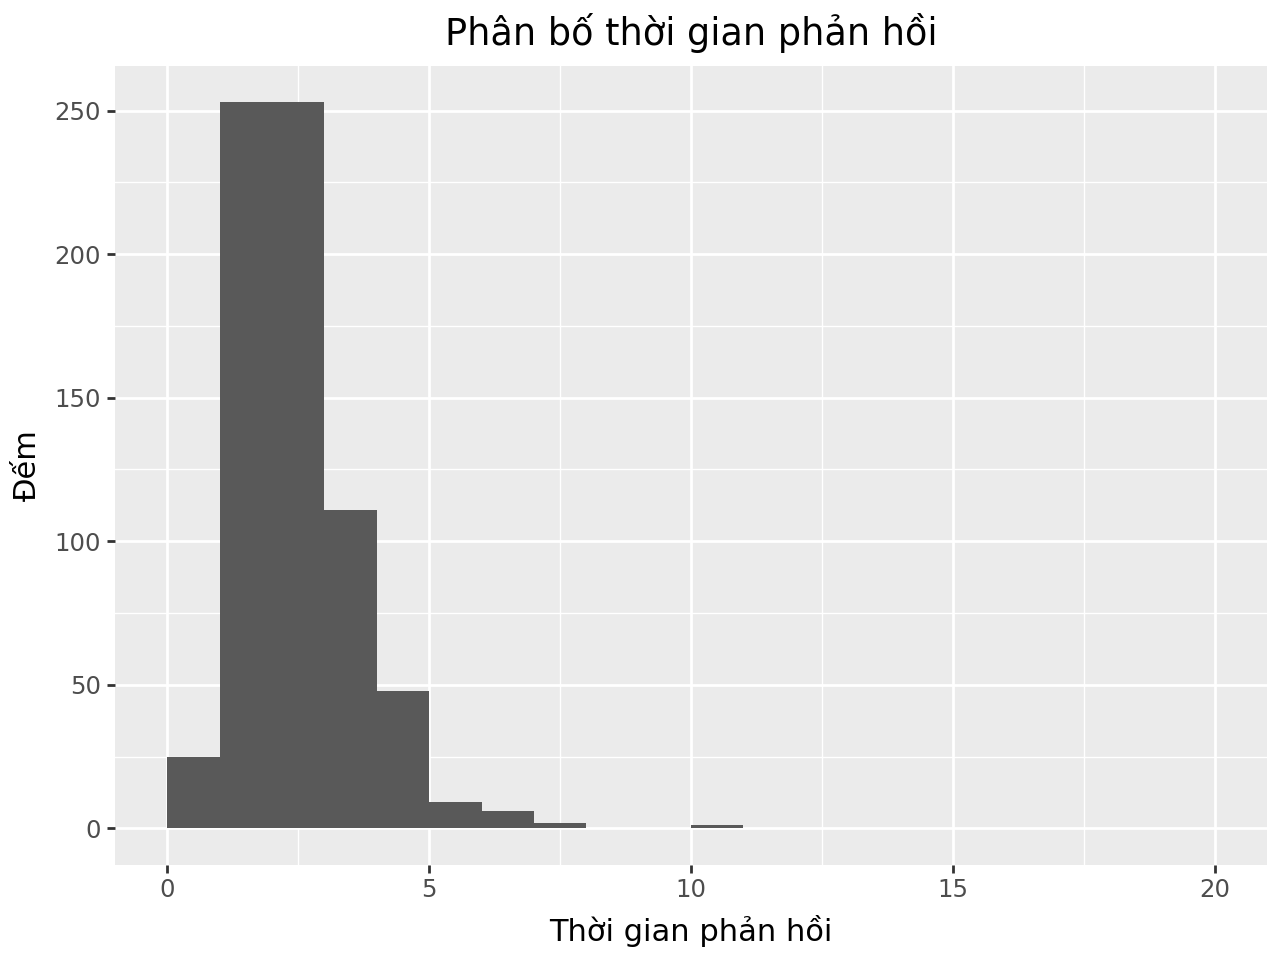

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\plotnine\layer.py:293: PlotnineWarning: stat_bin : Removed 4 rows containing non-finite values.


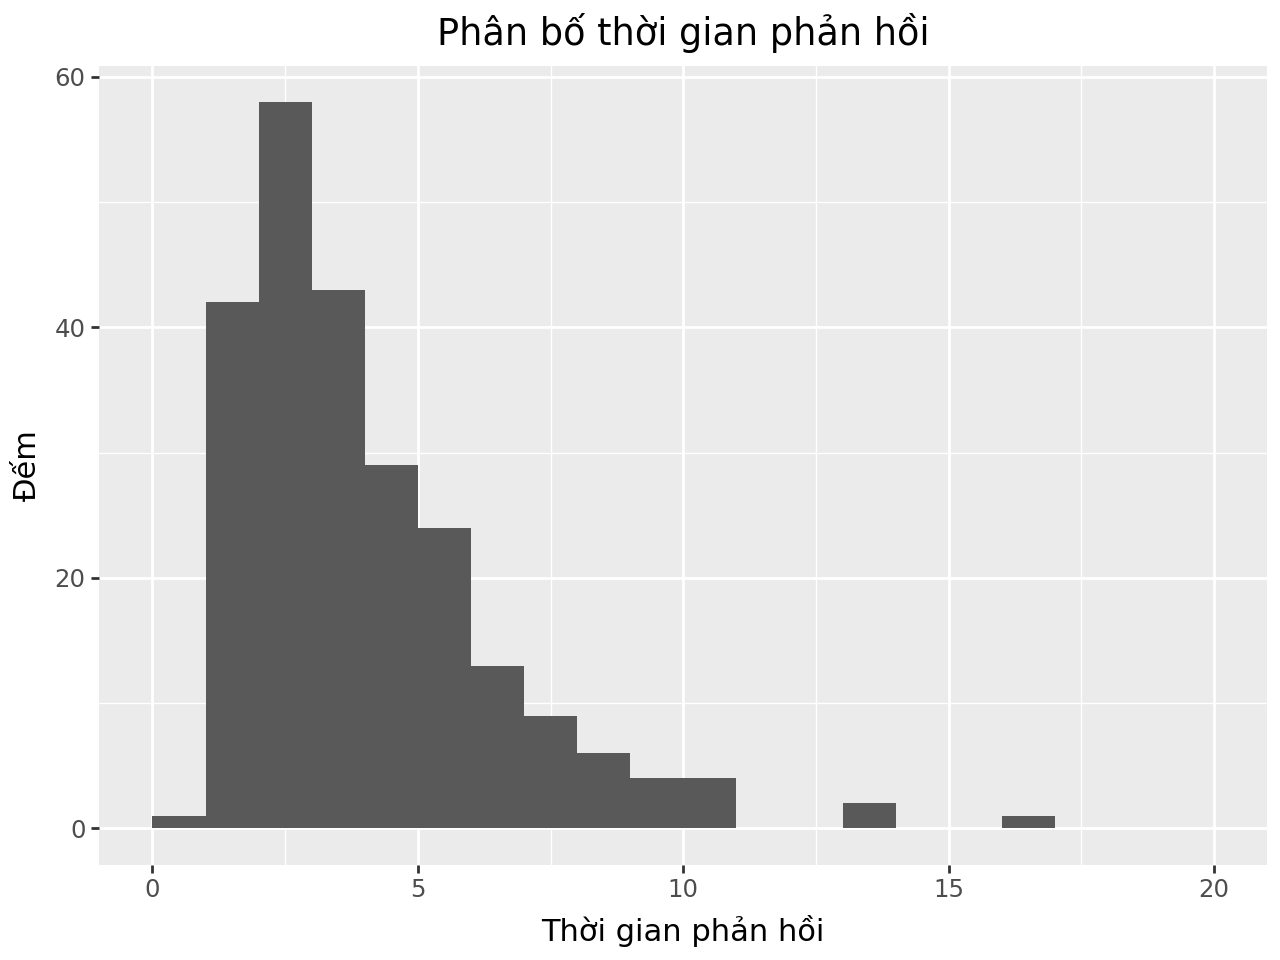

Số NaN: 16


task
Code explanation     4
FAQ                 12
Name: response_time_s, dtype: int64

In [66]:
# TODO: Bai 6, cau 1. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.
FAQ = (
    ggplot(
        raw6.query("task == 'FAQ'"),
        aes(x='response_time_s')
    )
    + geom_histogram(breaks=list(range(0, 21)))
    + labs(
        title="Phân bố thời gian phản hồi",
        x="Thời gian phản hồi",
        y="Đếm"
    )
)
display(FAQ)
CE = (
    ggplot(
        raw6.query("task == 'Code explanation'"),
        aes(x='response_time_s')
    )
    + geom_histogram(breaks=list(range(0, 21)))
    + labs(
        title="Phân bố thời gian phản hồi",
        x="Thời gian phản hồi",
        y="Đếm"
    )
)
display(CE)


print("Số NaN:",raw6['response_time_s'].isna().sum())
raw6.groupby("task")["response_time_s"].apply(lambda s: s.isna().sum())

**Bài làm / nhận xét của tôi:**
1. lọc truy vấn theo task
2. Trục x lấy từ cột 'respone_time_s' , khoảng chia là 1
3. Nhãn trục x là `Thời gian phản hồi` , trục y là biến `Đếm`.



### Câu 2
Báo cáo số hàng ban đầu, số thời gian thiếu và số lượt hợp lệ trong từng tác vụ. Vì sao một nhóm có cột cao hơn chưa chắc có phân phối tập trung hơn?

In [67]:
# TODO: Bai 6, cau 2. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.
summary  = raw6.groupby("task").agg(
    so_thoi_gian_thieu=("response_time_s", lambda s: s.isna().sum()),
    so_luot_hop_le=("response_time_s", "count")
)

summary

,so_thoi_gian_thieu,so_luot_hop_le
task,,
Code explanation,4,236
FAQ,12,708


**Bài làm / nhận xét của tôi:**

1. Số hàng ban đầu : 960
2. Xét từng tác vụ : 
    
    **FAQ** : số thời gian phản hồi bị NaN là 12, số lượt hợp lệ là 236.
    **CE** : số thời gian phản hồi bị NaN là 4, số lượt hợp lệ là 708.

### Câu 3
Vẽ lại trên thang mật độ phần trăm/giây, chuẩn hóa riêng trong từng tác vụ. Tính bảng tần số để kiểm tra diện tích mỗi histogram bằng 100%.

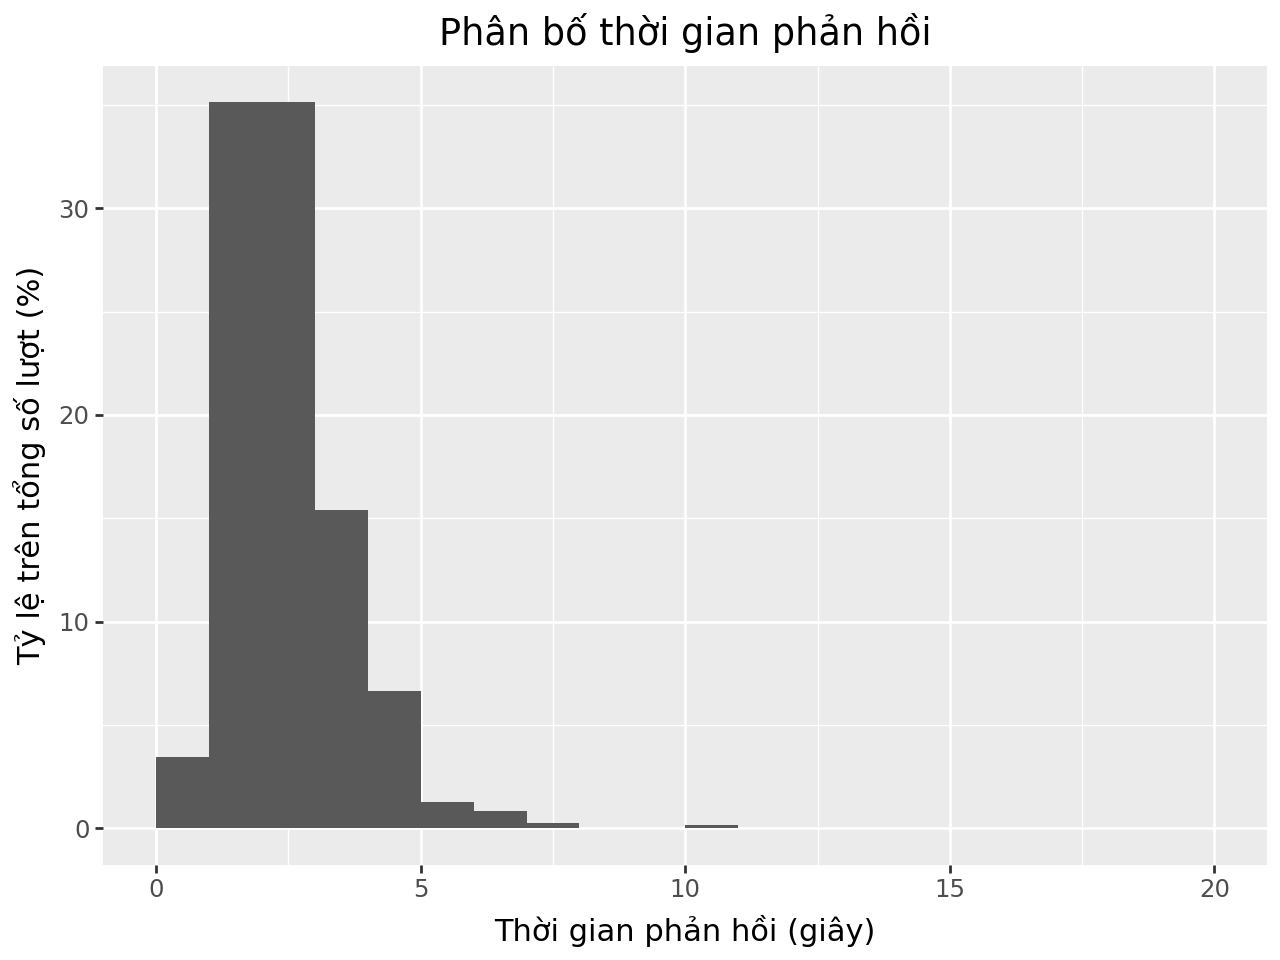

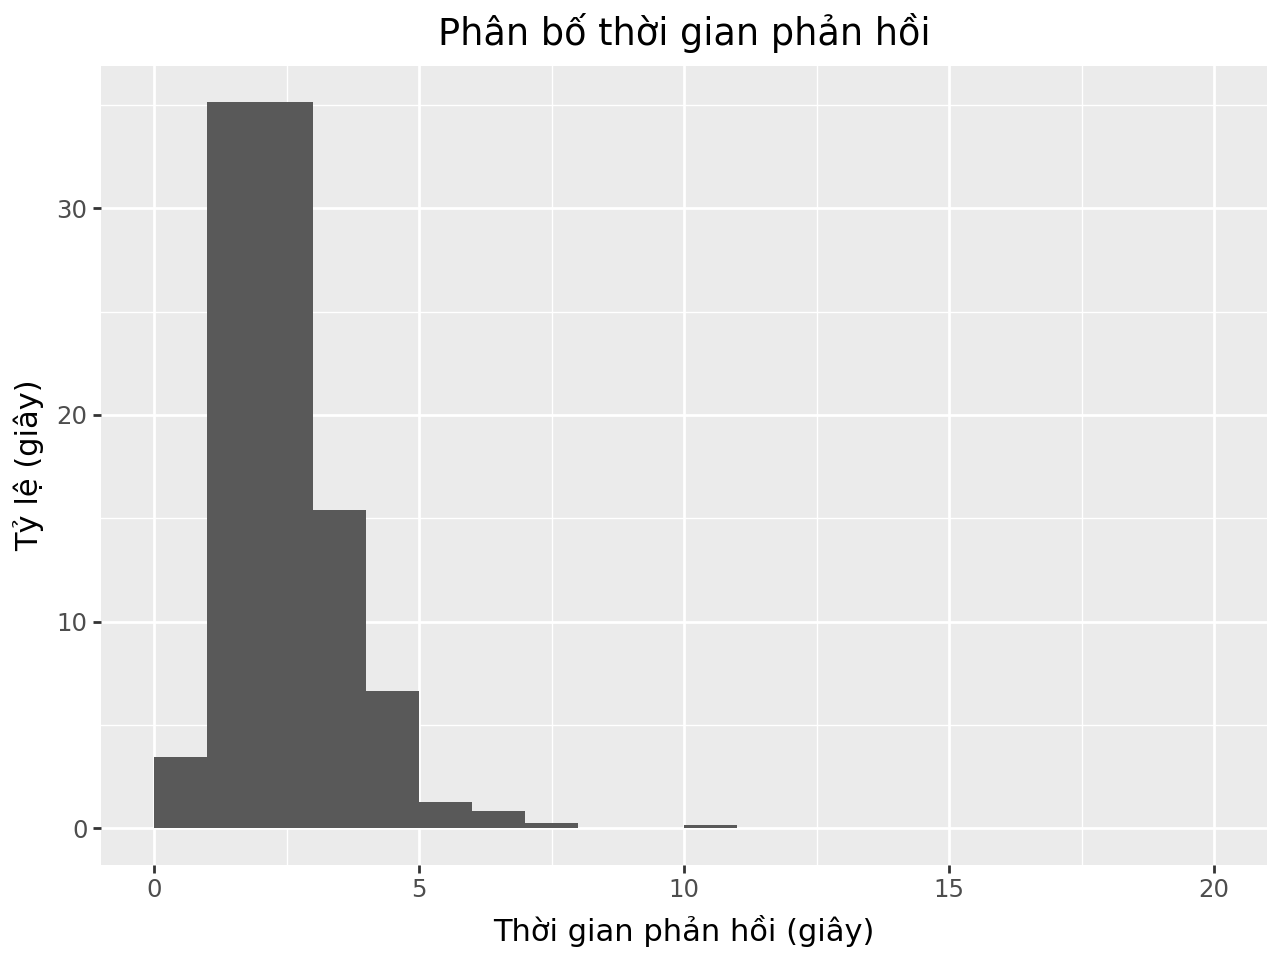

In [71]:
# TODO: Bai 6, cau 3. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.
faq = raw6.query("task == 'FAQ'").copy()

n_task = len(faq)
faq = faq.dropna(subset=["response_time_s"])
faq["ty_le_pct"] = 100 / n_task

FAQ = (
    ggplot(faq, aes(x="response_time_s", weight="ty_le_pct"))
    + geom_histogram(breaks=list(range(0, 21)))
    + labs(
        title="Phân bố thời gian phản hồi",
        x="Thời gian phản hồi (giây)",
        y="Tỷ lệ trên tổng số lượt (%)"
    )
)
display(FAQ)
ce = raw6.query("task == 'Code explanation'").copy()

n_task = len(ce)
ce = ce.dropna(subset=["response_time_s"])
ce["ty_le_pct"] = 100 / n_task

CE = (
    ggplot(faq, aes(x="response_time_s", weight="ty_le_pct"))
    + geom_histogram(breaks=list(range(0, 21)))
    + labs(
        title="Phân bố thời gian phản hồi",
        x="Thời gian phản hồi (giây)",
        y="Tỷ lệ (giây)"
    )
)
display(CE)


**Bài làm / nhận xét của tôi:**
Với mỗi task : 
1. Truy vấn loại task từ raw6, bỏ các hàng không hợp lệ.
2. Mật độ phần trăm/giây mỗi khoảng = đếm tần suất từng khoảng/tổng số tác vụ của task đó -> weight = 1/len(task) * 100
3. Vẽ histogram tương tự câu 1.


### Câu 4
Viết 4–6 câu so sánh vị trí, độ trải rộng, đuôi và vùng chồng lấp. Có thể bổ sung trung vị và khoảng tứ phân vị, nhưng không thay toàn bộ nhận xét bằng hai số trung bình.

**Bài làm / nhận xét của tôi:**

So sánh :

`Vị trí` : 2 tác vụ đều có dữ liệu phản hồi tập trung quanh giá trị 2-3s.

`Độ trải rộng` : Cả 2 histogram đều nhọn, dữ liệu tập trung mạnh, phần lớn tập trung trong khoảng 0-5s.

`Đuôi` : cả 2 histogram đều lệch phải, một vài ngoại lại ở 10-11s.

`Vùng chồng lấp` : Vùng chồng lấp lớn và hình dạng gần giống nhau -> 2 nhóm tác vụ có thời gian phản hồi gần giống nhau.

### Câu 5
Nếu dùng khoảng rộng 1 giây cho FAQ nhưng 3 giây cho giải thích mã, việc so sánh có vấn đề gì? Nêu cách trình bày giúp người đọc kiểm tra được kết luận.

**Bài làm / nhận xét của tôi:**

**Vấn đề** : Khoảng chia respone_time_s của 2 tác vụ đâng khác nhau -> nếu so sánh bằng chiều cao các cột có thể cho ra kết luận sai. Khi trình bày cần ghi rõ đại lượng trục y là count,% hay density.

## Bài 7 — Vì sao thời gian gán nhãn hay kết thúc bằng 0 hoặc 5?

Trong một đợt làm bộ ảnh huấn luyện, người tham gia ghi thời lượng phiên gán nhãn bằng hai cách: tự ước lượng (`Self-reported`) hoặc dùng bộ bấm giờ (`Stopwatch`). Tệp `exercise07_annotations.csv` có 420 phiên. Cột `duration_min` được lưu ở độ phân giải một phút; giá trị hợp lệ là số nguyên dương. Ô trống nghĩa là chưa ghi được thời lượng.

Ta muốn tìm hiểu *cách ghi số* có để lại dấu vết trên dữ liệu hay không. Không có bảng thời gian chuẩn độc lập để đối chiếu.

In [33]:
raw7 = pd.read_csv(DATA / "exercise07_annotations.csv")
display(raw7.head())
print("Kich thuoc:", raw7.shape)
# Hay kiem tra cac cot, don vi va chinh sach du lieu thieu truoc khi lam bai.

,id,recording_method,duration_min
0,L0001,Self-reported,35.0
1,L0002,Self-reported,55.0
2,L0003,Self-reported,40.0
3,L0004,Stopwatch,16.0
4,L0005,Stopwatch,69.0


Kich thuoc: (420, 3)


### Câu 1
Kiểm tra dữ liệu hợp lệ, báo cáo số phiên được giữ và tạo chữ số hàng đơn vị bằng phép chia lấy dư cho 10. Không làm tròn thêm dữ liệu.

In [34]:
# TODO: Bai 7, cau 1. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 2
Lập bảng số đếm và tỉ lệ cho đủ 10 chữ số 0–9; vẽ biểu đồ cột tỉ lệ.

In [35]:
# TODO: Bai 7, cau 2. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 3
Thêm mốc 10% vào biểu đồ và so sánh. Giải thích vì sao mốc “10 chữ số đều nhau” chỉ là tham chiếu mô tả, chưa phải kiểm định hay một quy luật bắt buộc.

In [36]:
# TODO: Bai 7, cau 3. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 4
Tính tỉ lệ thời lượng kết thúc bằng 0 hoặc 5. Có hiện tượng dồn số tại hai chữ số này không?

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 5
Lặp lại theo `recording_method`; chuẩn hóa riêng trong mỗi cách ghi. Báo cáo cả cỡ nhóm và tỉ lệ kết thúc bằng 0 hoặc 5.

In [37]:
# TODO: Bai 7, cau 5. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 6
Nêu ít nhất hai cơ chế hợp lý có thể tạo ra hiện tượng dồn số. Biểu đồ có đủ để nói người tham gia “ghi sai” hoặc “không làm việc thật” không? Cần thêm dữ liệu gì để phân biệt các cơ chế?

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

## Bài 8 — Một cụm điểm sát 70 có đáng nghi?

Tệp `exercise08_ai_projects.csv` ghi 240 sản phẩm AI nhỏ được đánh giá qua ba đợt. Mỗi hàng là một sản phẩm, với điểm chất lượng, độ ổn định và trình bày. Tổng điểm được tính theo

$$

\text{tổng}=0.5\,\text{chất lượng}+0.3\,\text{ổn định}+0.2\,\text{trình bày},

$$

rồi làm tròn một chữ số thập phân. Điểm ở thang 0--100; có một số ô thiếu trong bản trích. Mốc 70 được dùng làm mốc tham chiếu khi thảo luận sản phẩm.

Một thành viên nhìn biểu đồ gộp và nói: “Có một đỉnh ngay trên 70, chắc kết quả đã được sửa để qua mốc.” Hãy kiểm tra mức độ mà dữ liệu hỗ trợ phát biểu này.

In [38]:
raw8 = pd.read_csv(DATA / "exercise08_ai_projects.csv")
display(raw8.head())
print("Kich thuoc:", raw8.shape)
# Hay kiem tra cac cot, don vi va chinh sach du lieu thieu truoc khi lam bai.

,id,evaluation_round,quality_score,stability_score,presentation_score,total_score
0,P0001,Round 1,71.2,68.6,72.5,70.7
1,P0002,Round 1,54.8,57.3,49.3,54.4
2,P0003,Round 3,69.8,75.0,63.7,70.1
3,P0004,Round 1,65.1,66.7,62.3,NaN
4,P0005,Round 3,86.7,83.9,84.1,85.3


Kich thuoc: (240, 6)


### Câu 1
Vẽ histogram tổng điểm với các biên 0,5,10,...,100. Ghi số tổng điểm hợp lệ và không quy ô thiếu thành 0.

In [39]:
# TODO: Bai 8, cau 1. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 2
Vẽ lại với các biên 0,1,2,...,100; giữ cùng miền trục ngang. Chỉ ra những khoảng có số sản phẩm lớn.

In [40]:
# TODO: Bai 8, cau 2. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 3
Đặc điểm nào vẫn thấy ở cả hai cách chia? Đỉnh nhỏ hoặc khoảng trống nào phụ thuộc cách chia? Có thể khẳng định chính xác số mốt của một phân phối nền từ đây không?

In [41]:
# TODO: Bai 8, cau 3. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 4
Chia theo đợt đánh giá, dùng cùng biên và thang đo. Cụm quanh 70–73 đến chủ yếu từ đâu? Kiểm tra bằng số sản phẩm có tổng điểm thuộc khoảng từ 70 đến dưới 73 trong từng đợt.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 5
Chuyển ba cột điểm thành phần sang dạng dài, vẽ cùng một kiểu histogram. Mẫu hình gần 70 có chỉ xuất hiện ở tổng điểm không?

In [42]:
# TODO: Bai 8, cau 5. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 6
Viết kết luận không quá 120 từ: nêu bằng chứng mô tả, một số cơ chế khác có thể giải thích, và điều gì chưa thể kết luận về việc sửa kết quả.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

## Bài 9 — Cấu hình nào nhanh hơn: đọc bảng gộp hay bảng theo nhóm?

Một nhóm thử hai cấu hình triển khai A và B cho cùng loại trợ lý AI. Tệp `exercise09_deployments.csv` chỉ lưu 1.200 lượt **đã hoàn thành**, mỗi hàng là một lượt. Cột `input_length_group` ghi nhóm đầu vào `Short`, `Medium`, `Long`; `response_time_s` là thời gian hoàn thành. Các lượt ở hai cấu hình không được ghép cặp và cơ cấu độ dài không nhất thiết giống nhau.

Một bạn báo cáo: “Trung bình của A nhỏ hơn, vậy A luôn nhanh hơn B.” Trong bài này, mọi so sánh bằng số về “nhanh hơn” đều dùng **thời gian trung bình**; các hình phân phối cung cấp bối cảnh bổ sung.

In [43]:
raw9 = pd.read_csv(DATA / "exercise09_deployments.csv")
display(raw9.head())
print("Kich thuoc:", raw9.shape)
# Hay kiem tra cac cot, don vi va chinh sach du lieu thieu truoc khi lam bai.

,id,configuration,input_length_group,response_time_s
0,D0001,B,Long,6.61
1,D0002,B,Short,1.88
2,D0003,A,Short,1.27
3,D0004,A,Short,1.79
4,D0005,B,Long,8.04


Kich thuoc: (1200, 4)


### Câu 1
Tính số lượt, thời gian trung bình và trung vị theo cấu hình; vẽ boxplot hoặc histogram để so sánh phân phối gộp.

In [44]:
# TODO: Bai 9, cau 1. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 2
Lặp lại đúng các tóm tắt trên trong từng nhóm độ dài. Vẽ biểu đồ theo nhóm với cùng loại biểu đồ và thang đo.

In [45]:
# TODO: Bai 9, cau 2. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 3
So sánh dấu và độ lớn của chênh lệch trung bình A trừ B ở mức gộp và trong từng nhóm. Kết luận gộp có giữ cùng chiều trong mọi nhóm không?

In [46]:
# TODO: Bai 9, cau 3. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 4
Lập bảng tỉ phần các nhóm độ dài trong A và trong B. Dùng bảng này viết lại mỗi trung bình gộp thành trung bình có trọng số của ba trung bình nhóm.

In [47]:
# TODO: Bai 9, cau 4. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 5
Bộ dữ liệu này có sự đảo chiều theo nghĩa Simpson đối với trung bình hay chỉ là chênh lệch nhỏ đi? Giải thích tiêu chí; giảm độ lớn thôi đã đủ để gọi là đảo chiều chưa?

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 6
Vì chỉ có các lượt hoàn thành, có thể dùng kết quả để khẳng định cấu hình nào tốt hơn với mọi yêu cầu hoặc cấu hình gây ra thời gian chờ ngắn hơn không? Nêu dữ liệu hoặc cách đánh giá bổ sung cần thiết.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

## Bài 10 — Nhiều lượt tạo ảnh lỗi nhất có phải là dễ lỗi nhất?

Một dịch vụ tạo ảnh cho câu lạc bộ lưu toàn bộ 1.000 yêu cầu đã tiếp nhận trong đợt thử. Cột `concurrent_requests` là số yêu cầu *khác* đang được xử lý lúc yêu cầu mới đến; `failed`=1 nếu không trả được ảnh hợp lệ trong 60 giây, bằng 0 nếu trả được. Cột `processing_mode` có hai mức `Standard` và `Economy`. Mỗi yêu cầu được tính đúng một lần, kể cả yêu cầu thất bại.

Một bạn lọc riêng các lượt thất bại, thấy một khoảng tải có nhiều lượt nhất rồi nói: “Yêu cầu ở khoảng đó có khả năng thất bại cao nhất.” Hãy kiểm tra bằng cùng các khoảng tải $[0,10),[10,20),\ldots,[40,50)$.

In [48]:
raw10 = pd.read_csv(DATA / "exercise10_image_requests.csv")
display(raw10.head())
print("Kich thuoc:", raw10.shape)
# Hay kiem tra cac cot, don vi va chinh sach du lieu thieu truoc khi lam bai.

,id,concurrent_requests,processing_mode,failed
0,G0001,16,Economy,0
1,G0002,10,Standard,0
2,G0003,14,Economy,0
3,G0004,33,Standard,0
4,G0005,19,Standard,0


Kich thuoc: (1000, 4)


### Câu 1
Lọc các lượt thất bại và vẽ histogram tải với các biên đã cho. Hình này mô tả phân phối của tải trong tập quan sát nào?

In [49]:
# TODO: Bai 10, cau 1. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 2
Quay lại dữ liệu đầy đủ, đếm tất cả yêu cầu trong từng khoảng tải. Không dùng bảng đã lọc thất bại làm mẫu số.

In [50]:
# TODO: Bai 10, cau 2. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 3
Tính tỉ lệ thất bại trong mỗi khoảng. Viết bằng lời cả tử số và mẫu số. Quy định cách xử lý nếu một khoảng không có yêu cầu.

In [51]:
# TODO: Bai 10, cau 3. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 4
Vẽ hai biểu đồ riêng: số lượt thất bại và tỉ lệ thất bại theo khoảng tải. Ghi rõ đơn vị trục dọc.

In [52]:
# TODO: Bai 10, cau 4. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 5
Báo cáo khoảng có nhiều lượt thất bại nhất và khoảng có tỉ lệ thất bại cao nhất. Chúng có giống nhau trong dữ liệu này không?

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 6
Chỉ ra lỗi mẫu số trong câu kết luận ban đầu. Nêu thêm một ví dụ đời sống, ngoài bối cảnh tạo ảnh, có cùng lỗi suy luận.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

### Câu 7
Chia thêm theo chế độ xử lý, tính lại số yêu cầu và tỉ lệ thất bại trong từng tổ hợp chế độ–khoảng tải. Mẫu hình thay đổi thế nào? Không suy ra tác động nhân quả của chế độ.

In [53]:
# TODO: Bai 10, cau 7. Bo sung cac lenh o day.
# Khong doi du lieu goc de lam ket luan dep hon.

**Bài làm / nhận xét của tôi:**

_(Viết phép tính, mẫu số và phần giải thích ở đây.)_

## Trước khi nộp
Restart Kernel → Run All; lưu notebook sau khi có kết quả. Nộp các bài tính tay riêng. Các hình phải có đơn vị; các tỉ lệ phải có mẫu số. Không khẳng định nhân quả từ hình hoặc bảng mô tả.